# Modelos Supervisados - Métodos de Clasificación

# Caso -> **"Ascenso de trabajadores"**

## wd

In [ ]:
### Mounting Google Drive :
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
!pwd

In [ ]:
working_dir = "/content/drive/MyDrive/_PUCP_s/Cursos/1INF03_ADD/datos"
%cd $working_dir

In [ ]:
!pwd

In [ ]:
import pandas as pd

## Librerías y datos : "**datos_ascensoTrabajadores.csv**"

**Ascenso DeTrabajadores: Promoción Laboral**

El dataset *datos_ascensoTrabajadores.csv* contiene información de los trabajadores de determinada empresa. Se desea analizar la relación existente entre las diferentes características de cada trabajador respecto al hecho de haber sido promovidos de puesto.

El dataset contiene las siguientes variables:


VARIABLE | DESCRIPCION
--------|-------------
employee_id | Identificador del trabajador
department | Área de la empresa donde labora
region | Región de la empresa
education | Nivel de estudios alcanzado
gender | Género del trabajador
recruitment_channel | Canal de reclutamiento al ingresar a la empresa
no_of_trainings | Cantidad de entrenamientos en los que ha participado
age | Edad del trabajador
previous_year_rating | Puntuación alcanzada en evaluaciones anteriores
length_of_service | Años de servicio
KPIs_met_>80 | Ha obtenido KPI mayor a 80
awards_won |  Ha obtenido algún reconocimiento o premio en la empresa
is_promoted | Ha sido promovido de puesto


***"¿Podemos identificar a los empleados con mayor probabilidad de recibir un ascenso, utilizando su historial laboral y sus indicadores de rendimiento, sin generar conclusiones engañosas ni reproducir sesgos?"***

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
df = pd.read_csv('datos_ascensoTrabajadores.csv', sep=';')
print(df.shape)
df.head(5)

## Entendimiento de datos

Tipo de variables

In [ ]:
df.dtypes

In [ ]:
df.describe()

Cambiamos tipo de variables

In [ ]:
variable_s = ['employee_id', 'department', 'region',
    'education', 'gender',
    'recruitment_channel',
    'is_promoted',
    'KPIs_met_>80',
    'awards_won' ]

df[variable_s] = df[variable_s].astype('object')
df.dtypes

Renombramos las filas

In [ ]:
df.index = df['employee_id']
df.index.name = None
#df.set_index("employee_id")
df.drop(['employee_id'], axis=1, inplace=True)

df.head(5)

Tratamiento de valores vacíos

In [ ]:
nas = pd.DataFrame(df.isnull().sum()).sort_values(0,ascending=False)
nas.columns = ['nas']
nas['nas%'] = round(nas['nas']/df.shape[0], 2)
nas

In [ ]:
df.dropna(inplace=True)

nas = pd.DataFrame(df.isnull().sum()).sort_values(0,ascending=False)
nas.columns = ['nas']
nas['nas%'] = round(nas['nas']/df.shape[0], 2)
nas

Identificación de variables: Dependiente e Independientes

In [ ]:
# Variable Dependiente
y = df['is_promoted']
y

In [ ]:
y.value_counts()

In [ ]:
y.value_counts(normalize=True)*100

In [ ]:
# Variables Independientes
x = df.drop(['is_promoted'], axis=1)
print(x.shape)
x.head(5)

In [ ]:
x.nunique()                 # x['department'].value_counts()

"department" y "region" ->>>> Excluirlas o Agrupar sus categorías (x Criterios del estudio o matemáticamente)

Esta vez, optaremos por excluir estas dos variables, pero ya hemos visto cómo podemos transformarlas reagrupando las categorías de estos tipos de variables para poder incluirlas en los modelos.
* Tarea: Analizar otros escenarios transformando alguna de estas variables.

In [ ]:
# ...

In [ ]:
x.drop(['department', 'region'], axis=1, inplace=True)
x.nunique()

## Partición de los datos

Particionamos los datos en Entrenamiento y Prueba

In [ ]:
print(df.shape)

In [ ]:
from sklearn.model_selection import train_test_split

# Datasets de entrenamiento y prueba

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=20262)


## Preprocesamiento de datos

Esta vez, no estamos profundizando en el tratamiento de valores atípicos.

* Tarea: Analizar otros escenarios donde se apliquen técnicas para tratamiento de datos atípicos.

In [ ]:
# ...

Esta vez, optaremos por excluir los valores vacíos, pero ya hemos visto métodos de imputación que podríamos emplear.
* Tarea: Analizar otros escenarios donde se apliquen técnicas para imputación de datos vacíos.

In [ ]:
# ...

Identificamos y separamos las variables numéricas y categóricas

In [ ]:
x_numericas = x_train.select_dtypes(include='number')
print(x_numericas.shape)

x_categoricas = x_train.select_dtypes(include=['object', 'string'])
print(x_categoricas.shape)


In [ ]:
x_numericas.head(3)

In [ ]:
x_categoricas.head(3)

In [ ]:
x_numericas.describe()

In [ ]:
x_categoricas.nunique()                 # x_categoricas['department'].value_counts()

## Transformación de datos

### Scaler

In [ ]:
from sklearn.preprocessing import StandardScaler
import joblib

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train[ x_numericas.columns ])

x_train_scaled = pd.DataFrame(x_train_scaled,
                                 columns=x_numericas.columns,
                                 index=x_train[ x_numericas.columns ].index)


# Guardamos el scaler para después usarlo con test
joblib.dump(scaler, 'transform_scaler.pkl')

# scaler_loaded = joblib.load('transform_scaler.pkl')
# x_new_num_scaled = scaler_loaded.transform(x_new_num)

In [ ]:
x_train.head(3)

In [ ]:
x_train_scaled.head(3)

### Dummies

Generamos variables dummies con las variables categóricas

In [ ]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
import pandas as pd
import joblib

ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False, drop='first')

ohe.fit(x_train[ x_categoricas.columns ])

x_train_ohe = ohe.transform(x_train[  x_categoricas.columns  ])

cols = ohe.get_feature_names_out(  x_categoricas.columns  )
x_train_ohe = pd.DataFrame(x_train_ohe, columns=cols, index=x_train.index)

# Guardamos el ohe para después usarlo con test
joblib.dump(ohe, 'transform_ohe_encoder.pkl')

# ohe_loaded = joblib.load('ohe_encoder.pkl')
# x_new_ohe = ohe_loaded.transform(new_df)


In [ ]:
x_train.head(3)

In [ ]:
x_train_ohe.head(3)

Tarea: Construir 2 sets de datos, para probar diferentes escenarios de entrenamiento:

a) transformando educación como dummies, b) transformando educación como ordinal (numérica[?])

In [ ]:
# ...

Con el hiperparámetro "drop='first'" hemos excluído las categorías redundantes

(y nos quedamos con 'p-1' dummies en todas las variables categóricas)

In [ ]:
x_train_ohe.columns

### Concat

Verificamos tipo de variables

In [ ]:
print(x_train.shape)
print(x_train_scaled.shape)
print(x_train_ohe.shape)

x_train_v2 = pd.concat([x_train_scaled,
                             x_train_ohe], axis=1)
print(x_train_v2.shape)

In [ ]:
x_train_v2.dtypes

In [ ]:
nas = pd.DataFrame(x_train_v2.isnull().sum()).sort_values(0,ascending=False)
nas.columns = ['nas']
nas['nas%'] = round(nas['nas']/x_train_v2.shape[0], 2)
nas

In [ ]:
x_train_v2.head(3)

## Balanceo de datos

In [ ]:
!pip install -U imbalanced-learn

In [ ]:
print(x.shape)
print(" ")
print(x_train.shape)
print(x_train_v2.shape)
print(" ")
print(y_train.shape)


In [ ]:
pd.DataFrame(y_train).value_counts()

In [ ]:
pd.DataFrame(y_train).value_counts(normalize=True)*100

In [ ]:
from imblearn.combine import SMOTETomek
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import TomekLinks
from collections import Counter

**SMOTE**: aumenta las muestras de las clases minoritarias generando ejemplos sintéticos.

**TomekLinks**: elimina pares de observaciones de clases diferentes que están muy próximas entre sí, ayudando a limpiar las fronteras.

https://imbalanced-learn.org/stable/references/generated/imblearn.combine.SMOTETomek.html#imblearn.combine.SMOTETomek

**Tabla de los parámetros propios de SMOTETomek**

| Parámetro          | Descripción |
|--------------------|-------------|
| sampling_strategy  | Define la estrategia de sobremuestreo del SMOTE predeterminado. |
| random_state       | Controla la aleatoriedad para obtener resultados reproducibles. |
| smote              | Permite proporcionar un objeto SMOTE personalizado. |
| tomek              | Permite proporcionar un objeto TomekLinks personalizado. |
| n_jobs             | En las versiones que lo admiten, controla el paralelismo de los componentes compatibles. |

In [ ]:
os_us = SMOTETomek(random_state=20262, sampling_strategy='all')

x_train_v3, y_train_v3 = os_us.fit_resample(x_train_v2, y_train)

In [ ]:
print(y_train.value_counts())
print(y_train_v3.value_counts())

In [ ]:
os_us = SMOTETomek(
    random_state=20262,

    smote=SMOTE(
        sampling_strategy='all',
        random_state=20262
    ),

    tomek=TomekLinks(
        sampling_strategy='auto'
    )
)

x_train_v3, y_train_v3 = os_us.fit_resample(x_train_v2, y_train)

In [ ]:
print(y_train.value_counts())
print(y_train_v3.value_counts())

| Parámetro                         | Descripción |
|-----------------------------------|-------------|
| random_state=20262                | Establece la semilla aleatoria del componente predeterminado de SMOTETomek. |
| smote=SMOTE(...)                  | Configura el componente encargado de generar muestras sintéticas. |
| SMOTE(sampling_strategy='all')    | Sobremuestrea todas las clases. |
| SMOTE(random_state=20262)         | Establece la semilla aleatoria de SMOTE. |
| tomek=TomekLinks(...)             | Configura el componente encargado de limpiar pares Tomek. |
| TomekLinks(sampling_strategy='auto') | Permite eliminar observaciones de todas las clases excepto la minoritaria, cuando forman parte de pares Tomek. |

**Tabla de sampling_strategy en SMOTE**

| sampling_strategy | Descripción |
|-------------------|-------------|
| 'auto'            | Equivale a 'not majority': sobremuestrea todas las clases excepto la mayoritaria. |
| 'minority'        | Sobremuestrea únicamente la clase minoritaria. |
| 'not minority'    | Sobremuestrea todas las clases excepto la minoritaria. |
| 'not majority'    | Sobremuestrea todas las clases excepto la mayoritaria. |
| 'all'             | Sobremuestrea todas las clases, incluida la mayoritaria. |
| dict              | Permite especificar el número deseado de muestras para determinadas clases. |
| float             | En clasificación binaria, establece la proporción deseada entre la clase minoritaria y la mayoritaria. |

**Tabla de sampling_strategy en TomekLinks**

| sampling_strategy | Descripción |
|-------------------|-------------|
| 'auto'            | Equivale a 'not minority': elimina observaciones de todas las clases excepto la minoritaria, cuando forman parte de pares Tomek. |
| 'majority'        | Elimina únicamente observaciones de la clase mayoritaria que forman parte de pares Tomek. |
| 'not minority'    | Permite eliminar observaciones de todas las clases excepto la minoritaria. |
| 'not majority'    | Permite eliminar observaciones de todas las clases excepto la mayoritaria. |
| 'all'             | Permite eliminar observaciones de todas las clases que forman parte de pares Tomek, incluida la minoritaria. |
| list              | Permite especificar directamente las clases que pueden tener observaciones eliminadas. |

## Transformaciones a 'x_test' para Predicciones

In [ ]:
# scaler_loaded = joblib.load('transform_scaler.pkl')
x_test_scaled = scaler.transform(x_test[x_numericas.columns])

x_test_scaled = pd.DataFrame(x_test_scaled,
                                 columns=x_numericas.columns,
                                 index=x_test[ x_numericas.columns ].index)

print(x_test.shape)
print(x_test_scaled.shape)

In [ ]:
# ohe_loaded = joblib.load('ohe_encoder.pkl')
x_test_ohe = ohe.transform(x_test[x_categoricas.columns])

cols = ohe.get_feature_names_out(  x_categoricas.columns  )
x_test_ohe = pd.DataFrame(x_test_ohe, columns=cols, index=x_test.index)

print(x_test.shape)
print(x_test_ohe.shape)

In [ ]:
print(x_test.shape)
print(x_test_scaled.shape)
print(x_test_ohe.shape)

x_test_concat = pd.concat([x_test_scaled,
                             x_test_ohe], axis=1)
print(x_test_concat.shape)

## Modelo 1: Regresión Logística

In [ ]:
from sklearn.linear_model import LogisticRegression

modelo1 = LogisticRegression(random_state=20262, fit_intercept=True)  # penalty='l2', solver='liblinear'

Seleccionamos parámetros con GridSearchCV

In [ ]:
param_dist = {
    "C": [1, 2, 3, 4, 5],
    "max_iter": [50, 100, 200, 500]
}

In [ ]:
#import random
#param_dist = {"C": [i+1 for i in range(0, 5)],          # valores pequeños significan regularización más fuerte  (regularizar = penalizar el sobreajuste) [es útil con gran cantidad de variables]
#              "max_iter": [i+1 for i in range(9, 100)]  # Cantidad máxima de iteraciones
#              }

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV

skf = StratifiedKFold(n_splits=5, random_state=20262, shuffle=True)

grid = GridSearchCV( modelo1, param_dist, cv=skf.split(x_train_v3, y_train_v3), n_jobs=-1, verbose=1)

grid.fit(x_train_v3, y_train_v3)

print(grid.best_params_)

In [ ]:
param = grid.best_params_
param

Entrenamos el modelo

In [ ]:
modelo1 = LogisticRegression(random_state=20262, fit_intercept=True, **param)

modelo1.fit(x_train_v3, y_train_v3)

In [ ]:
modelo1.score(x_train_v3, y_train_v3)

In [ ]:
y_predict_modelo1 = modelo1.predict(x_test_concat)
y_predict_modelo1

In [ ]:
pd.DataFrame(y_predict_modelo1).value_counts()

In [ ]:
pd.DataFrame(y_test).value_counts()

In [ ]:
modelo1.intercept_

In [ ]:
modelo1.coef_

In [ ]:
dir(modelo1)

In [ ]:
#modelA = x_train_all_smote_scaled, y_train_all_smote
#modelo1.fit().summary()

Calculamos accuracy de la predicción

In [ ]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

accuracy_score(y_test, y_predict_modelo1)

Calculamos accuracy con Cross Validation

In [ ]:
from sklearn.model_selection import cross_val_score

scores_res = cross_val_score(modelo1, x_train_v3, y_train_v3, cv=10)
print("Accuracy de los 10 folds:", scores_res)
print("Accuracy Mean: {:.3f} (std: {:.3f})".format(scores_res.mean(), scores_res.std()) )

In [ ]:
# Confusion matrix
print(pd.crosstab(y_test, y_predict_modelo1))

Cálculos que se pueden obtener de la Matriz de Confusión:

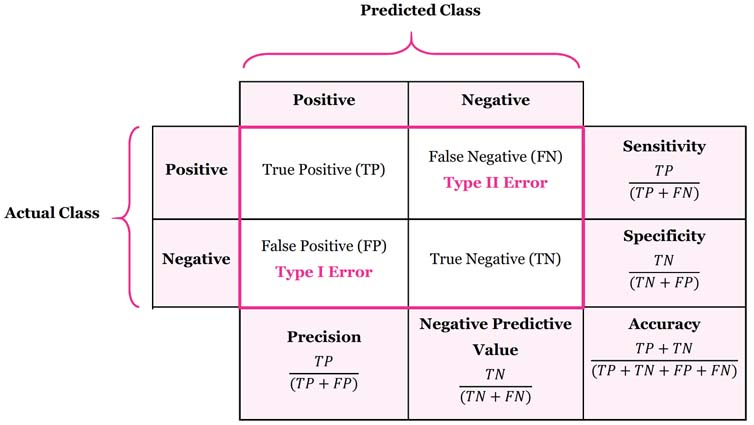

In [ ]:
print(x_train_v3.columns)
print(modelo1.coef_)
print(modelo1.intercept_)

In [ ]:
# Construimos la matriz de confusión

from sklearn.metrics import confusion_matrix

confusion_matrix(y_true=y_test, y_pred=y_predict_modelo1)


In [ ]:
import seaborn as sns; sns.set()
import matplotlib.pyplot as plt

sns.heatmap(confusion_matrix(y_true=y_test, y_pred=y_predict_modelo1), square=False, annot=True, fmt='d', cbar=True)
plt.xlabel('true label')
plt.ylabel('predicted label');

Guardamos el modelo

In [ ]:
import pickle
pickle.dump(modelo1, open('s7b_modelo1', 'wb'))

Realizamos predicciones con el modelo guardado

In [ ]:
import_modelo1 = pickle.load(open('s7b_modelo1', 'rb'))

result = import_modelo1.predict(x_test_concat)

pd.DataFrame(result).value_counts()

## Modelo 2 - KNN Classifier

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

modelo2 = KNeighborsClassifier( )

Seleccionamos parámetros con GridSearchCV

In [ ]:
param_dist = {
    "n_neighbors": [4, 8, 12, 16, 20],
    "p": [0, 1, 2, 3]
}

In [ ]:
#import random
#param_dist = {"n_neighbors": [i+1 for i in range(4, 20)] , # cantidad de vecinos más cercanos
#              "p": [i+1 for i in range(0, 2)]             # tipo de distancia a utilizar -> 1 : manhattan_distance, 2 : euclidean_distance
#              }

In [ ]:
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV

skf = StratifiedKFold(n_splits=5, random_state=20262, shuffle=True)

grid = GridSearchCV( modelo2, param_dist, cv=skf.split(x_train_v3, y_train_v3), n_jobs=-1, verbose=1)

grid.fit(x_train_v3, y_train_v3)

print(grid.best_params_)

In [ ]:
param = grid.best_params_
param

Entrenamos el modelo

In [ ]:
modelo2 = KNeighborsClassifier(**param)

modelo2.fit(x_train_v3, y_train_v3)

In [ ]:
modelo2.score(x_train_v3, y_train_v3)

In [ ]:
y_predict_modelo2 = modelo2.predict(x_test_concat)
y_predict_modelo2

In [ ]:
pd.DataFrame(y_predict_modelo2).value_counts()

Calculamos accuracy de la predicción

In [ ]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

accuracy_score(y_test, y_predict_modelo2)

Calculamos accuracy con Cross Validation

In [ ]:
from sklearn.model_selection import cross_val_score

scores_res = cross_val_score(modelo2, x_train_v3, y_train_v3, cv=10)
print("Accuracy de los 10 folds:", scores_res)
print("Accuracy Mean: {:.3f} (std: {:.3f})".format(scores_res.mean(), scores_res.std()) )

In [ ]:
# Confusion matrix
print(pd.crosstab(y_test, y_predict_modelo2))

Cálculos que se pueden obtener de la Matriz de Confusión:

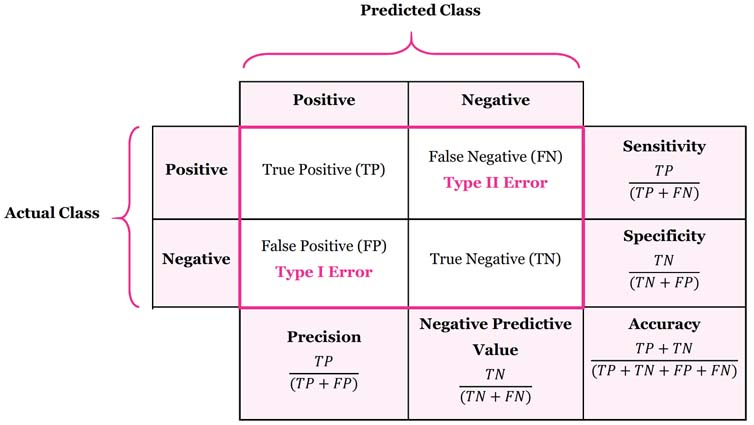

Guardamos el modelo

In [ ]:
import pickle
pickle.dump(modelo2, open('s7b_modelo2', 'wb'))

Realizamos predicciones con el modelo guardado

In [ ]:
import_modelo2 = pickle.load(open('s7b_modelo2', 'rb'))

result = import_modelo2.predict(x_test_concat)

pd.DataFrame(result).value_counts()

## Modelo 3 - Support Vector Classifier

In [ ]:
from sklearn.svm import SVC

modelo3 = SVC(random_state=20262)

Seleccionamos parámetros con GridSearchCV

In [ ]:

param_dist = {
    'C': [1], #[0.1, 1, 10],             # Parámetro de regularización. Controla la penalización por error
    'kernel': ['linear'], #['linear', 'rbf']   #Tipo de función núcleo para transformar los datos.
    #'gamma': ['auto']              # 'scale'
}

| Parámetro  | Valores típicos                   | Uso                    |
| ---------- | --------------------------------- | ------------------------------------- |
| **C**      | `[0.01, 0.1, 1, 10, 100]`         | Regularización, controla sobreajuste  |
| **kernel** | `['linear', 'rbf', 'poly']`       | Tipo de transformación                |
| **gamma**  | `['scale', 'auto', 0.01, 0.1, 1]` | Controla la flexibilidad del kernel   |
| **degree** | `[2, 3, 4]`                       | Solo para `poly`, grado del polinomio |
| **coef0**  | `[0.0, 0.1, 0.5]`                 | Ajusta kernel para `poly` y `sigmoid` |


| Parámetro        | Significado / Uso                                             | Valores Típicos                             | Significado de los Valores Típicos                                                                                                                                    |
| ---------------- | ------------------------------------------------------------- | ------------------------------------------- | --------------------------------------------------------------------------------------------------------------------------------------------------------------------- |
| **C**            | Controla la regularización; penaliza errores de clasificación | 0.01, 0.1, 1, 10, 100                       | Valores bajos → más margen, tolera errores (más generalización). Valores altos → ajuste estricto, puede sobreajustar                                                  |
| **kernel**       | Tipo de función núcleo para transformar los datos             | 'linear', 'rbf', 'poly', 'sigmoid'          | 'linear': frontera lineal. 'rbf': no lineal, flexible. 'poly': polinomial. 'sigmoid': función sigmoide (como una neurona)                                             |
| **gamma**        | Controla la influencia de cada punto en kernels no lineales   | 'scale' (por defecto), 'auto', 0.01, 0.1, 1 | 'scale': inverso del producto de features × varianza (equilibrado). 'auto': inverso del número de features. Valores numéricos altos → influencia local, bajo → global |
| **degree**       | Grado del polinomio para kernel 'poly'                        | 2, 3, 4                                     | Número que indica el grado del polinomio. Mayor grado = modelo más complejo                                                                                           |
| **coef0**        | Parámetro independiente para kernels 'poly' y 'sigmoid'       | 0.0, 0.1, 0.5                               | Controla la flexibilidad del kernel. Valores mayores aumentan el efecto independiente del polinomio o sigmoide                                                        |
| **shrinking**    | Heurística para acelerar el entrenamiento                     | True, False                                 | True: usa heurística para acelerar, recomendado usar True                                                                                                             |
| **probability**  | Calcula probabilidades de predicción                          | True, False                                 | True: habilita cálculo de probabilidades (más lento)                                                                                                                  |
| **tol**          | Tolerancia para el criterio de parada                         | 1e-3, 1e-4                                  | Valores más pequeños implican mayor precisión y más tiempo                                                                                                            |
| **class_weight** | Ajusta peso de clases en casos de desbalanceo                 | 'balanced', dict con pesos                  | 'balanced': ajusta automáticamente según frecuencia de clases                                                                                                         |


In [ ]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV

skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=20262)

grid = GridSearchCV(modelo3, param_dist, cv=skf.split(x_train_v3, y_train_v3), n_jobs=-1, verbose=1)
grid.fit(x_train_v3, y_train_v3)

print(grid.best_params_)

In [ ]:
print("Mejores hiperparámetros:", grid.best_params_)
param = grid.best_params_
param

Entrenamos el modelo

In [ ]:
modelo3 = SVC(random_state=20262, **param)

modelo3.fit(x_train_v3, y_train_v3)

In [ ]:
modelo3.score(x_train_v3, y_train_v3)

In [ ]:
y_predict_modelo3 = modelo3.predict(x_test_concat)
y_predict_modelo3

In [ ]:
pd.DataFrame(y_predict_modelo3).value_counts()

Calculamos accuracy de la predicción

In [ ]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

accuracy_score(y_test, y_predict_modelo3)

Calculamos accuracy con Cross Validation

In [ ]:
from sklearn.model_selection import cross_val_score

scores_res = cross_val_score(modelo3, x_train_v3, y_train_v3, cv=10)
print("Accuracy de los 10 folds:", scores_res)
print("Accuracy Mean: {:.3f} (std: {:.3f})".format(scores_res.mean(), scores_res.std()) )

In [ ]:
# Confusion matrix
print(pd.crosstab(y_test, y_predict_modelo3))

Cálculos que se pueden obtener de la Matriz de Confusión:

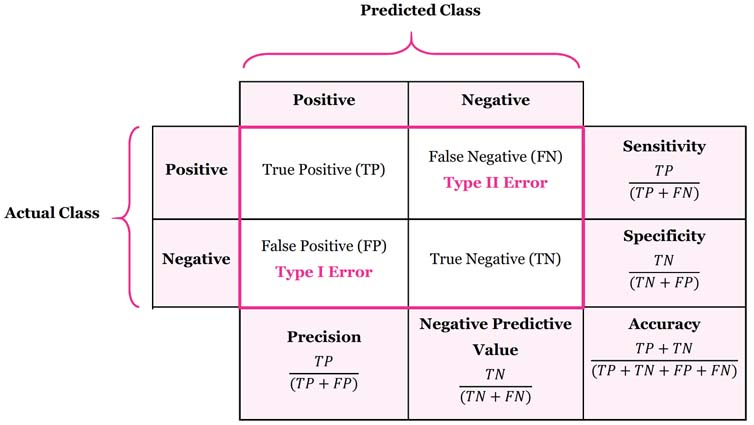

Guardamos el modelo

In [ ]:
import pickle
pickle.dump(modelo3, open('s7b_modelo3', 'wb'))

Realizamos predicciones con el modelo guardado

In [ ]:
import_modelo3 = pickle.load(open('s7b_modelo3', 'rb'))

result = import_modelo3.predict(x_test_concat)

pd.DataFrame(result).value_counts()